# Praktikum 4

In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

raw_df = pd.read_csv('burnout_dataset1.csv')
# Gunakan fitur numerik prediktor tanpa Burnout_Score dan Person_ID
num_cols = [c for c in raw_df.select_dtypes(include=[np.number]).columns if c not in ['Person_ID', 'Burnout_Score']]
df_num = raw_df[num_cols + ['Burnout_Risk']].copy()
df_num[num_cols] = df_num[num_cols].fillna(df_num[num_cols].median())

# Sampel stratified 4000 baris agar GridSearchCV berjalan cepat dan representatif
df_samp, _ = train_test_split(df_num, train_size=4000, random_state=42, stratify=df_num['Burnout_Risk'])
X = df_samp[num_cols].to_numpy()
y = df_samp['Burnout_Risk'].to_numpy()
target_names = np.array(['High', 'Low', 'Moderate'])
y_idx = np.array([np.where(target_names == val)[0][0] for val in y])

print('Kelas target:', target_names)
print('Jumlah kelas:', len(target_names))
print('Dimensi fitur:', X.shape)

Kelas target: ['High' 'Low' 'Moderate']
Jumlah kelas: 3
Dimensi fitur: (4000, 19)


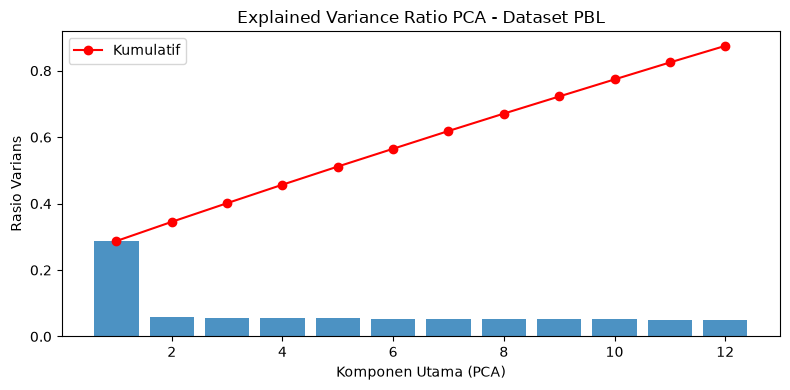

In [2]:
from matplotlib import pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Visualisasi proporsi varians yang dijelaskan oleh komponen PCA pada Dataset PBL
X_std = StandardScaler().fit_transform(X)
pca_viz = PCA(n_components=12, random_state=42).fit(X_std)

plt.figure(figsize=(8, 4))
plt.bar(range(1, 13), pca_viz.explained_variance_ratio_, alpha=0.8)
plt.plot(range(1, 13), np.cumsum(pca_viz.explained_variance_ratio_), marker='o', color='red', label='Kumulatif')
plt.xlabel('Komponen Utama (PCA)')
plt.ylabel('Rasio Varians')
plt.title('Explained Variance Ratio PCA - Dataset PBL')
plt.legend()
plt.tight_layout()
plt.show()

In [3]:
from sklearn.svm import SVC
from sklearn.decomposition import PCA as RandomizedPCA
from sklearn.pipeline import make_pipeline

scaler = StandardScaler()
pca = RandomizedPCA(n_components=12, whiten=True, random_state=42)
svc = SVC(kernel='rbf', class_weight='balanced')

# Pipeline untuk standardisasi, reduksi dimensi PCA, dan klasifikasi SVC
model = make_pipeline(scaler, pca, svc)

In [4]:
# pemisahan data training dan data testing
Xtrain, Xtest, ytrain, ytest = train_test_split(X, y_idx, random_state=42, stratify=y_idx)

In [5]:
from sklearn.model_selection import GridSearchCV
param_grid = {'svc__C': [1, 5, 10, 50],
              'svc__gamma': [0.001, 0.01, 0.05, 0.1]}
grid = GridSearchCV(model, param_grid, cv=5)

grid.fit(Xtrain, ytrain)
print(grid.best_params_)
print(grid.best_score_)

{'svc__C': 5, 'svc__gamma': 0.001}
0.8073333333333332


In [6]:
model = grid.best_estimator_
yfit = model.predict(Xtest)

In [7]:
# Ringkasan sampel prediksi pada data uji
hasil_sampel = pd.DataFrame({
    'Aktual': target_names[ytest[:15]],
    'Prediksi': target_names[yfit[:15]],
    'Sesuai': ytest[:15] == yfit[:15]
})
hasil_sampel

,Aktual,Prediksi,Sesuai
0,High,Moderate,False
1,Low,Low,True
2,Moderate,Moderate,True
3,Moderate,Moderate,True
4,High,High,True
5,High,High,True
6,Low,Low,True
7,Low,Low,True
8,High,Moderate,False
9,Low,Low,True


In [8]:
from sklearn.metrics import classification_report
print(classification_report(ytest, yfit, target_names=target_names))

              precision    recall  f1-score   support

        High       0.83      0.78      0.81       197
         Low       0.91      0.82      0.86       508
    Moderate       0.63      0.75      0.68       295

    accuracy                           0.79      1000
   macro avg       0.79      0.79      0.78      1000
weighted avg       0.81      0.79      0.80      1000



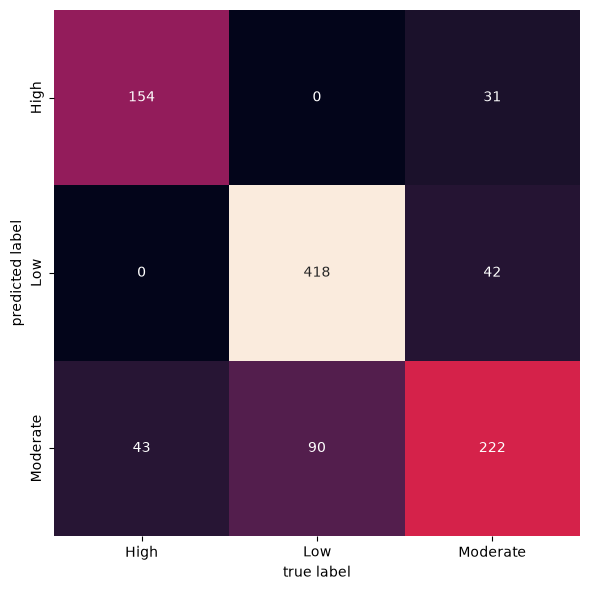

In [9]:
# bentuk confusion matrix
from sklearn.metrics import confusion_matrix
import seaborn as sns

mat = confusion_matrix(ytest, yfit)
plt.figure(figsize=(8, 6))
sns.heatmap(mat.T, square=True, annot=True, fmt='d', cbar=False,
            xticklabels=target_names,
            yticklabels=target_names)
plt.xlabel('true label')
plt.ylabel('predicted label')
plt.tight_layout()
plt.show()